# Sri Lankan Used Car Price Prediction
### New algorithm (LightGBM) + Explainability (SHAP, LIME, PDP) + App + MLOps

Goal: predict a fair asking price for a used car in Sri Lanka, so a buyer can check if a listing is over-priced.

Dataset: 18,938 car listings from a Sri Lankan classifieds site (Feb–Aug 2021). Taken from github.com/DavidR0/Car-Price-Prediction (originally from Kaggle). Only the CSV is reused.

Task: **regression** (target = `price` in Rs).

New algorithm: **LightGBM** (not covered in lectures). Models covered in lectures (Linear Regression, SVM, Decision Tree, Random Forest, XGBoost) are used as benchmarks.

Run from the project folder (needs `data/` and `src/`).

---

In [1]:
# install packages (comment out if already installed)

!pip -q install -r requirements.txt


[notice] A new release of pip is available: 25.3 -> 26.2.2
[notice] To update, run: C:\Users\sajan\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
DATA_PATH = "data/dataset_vehicles.csv"

rs_millions = mtick.FuncFormatter(lambda v, _: f"{v/1e6:,.0f}M")

## 1) Load dataset & first look

In [3]:
df_raw = pd.read_csv(DATA_PATH)

print("Shape:", df_raw.shape)
display(df_raw.head(3))
df_raw.info()

Shape: (18938, 19)


,Title,Sub_title,Price,Brand,Model,Edition,Year,Condition,Transmission,Body,Fuel,Capacity,Mileage,Location,Description,Post_URL,Seller_name,Seller_type,published_date
0,Micro Panda Auto 2019 for sale,"Posted on 02 Jul 6:27 am, Kesbewa, Colombo","Rs 2,795,000",Micro,Panda,Auto,2019,Used,Automatic,Hatchback,Petrol,"1,000 cc","14,000 km","Kesbewa, Colombo",â¤ Auto Auto Autoâ¤ Micro Panda CBH-xxxx 201...,ad_cb75f364c0,seller_9cc45b4178,Premium-Member,2021-07-02 06:27:00
1,Toyota GT86 Company Maintained 2013 for sale,"Posted on 15 Jun 7:38 pm, Rajagiriya, Colombo","Rs 11,500,000",Toyota,GT86,Company Maintained,2013,Used,Automatic,CoupÃ©/Sports,Petrol,"2,000 cc","27,000 km","Rajagiriya, Colombo",Toyota Gt86 Company maintained2013 Manufacture...,ad_05bc692686,seller_43cb56fc7f,Premium-Member,2021-06-15 19:38:00
2,"Toyota IST FL , GRADE 2003 for sale","Posted on 05 Jul 1:36 pm, Marawila, Puttalam","Rs 3,300,000",Toyota,IST,"FL , GRADE",2003,Used,Automatic,Hatchback,Petrol,"1,300 cc","150,000 km","Marawila, Puttalam",TOYOTA ISTFL GRADEKD ; >>>> NUMBERYOM 2003RAGE...,ad_94273f047e,seller_8d5c169aaa,Premium-Member,2021-07-05 13:36:00


<class 'pandas.DataFrame'>
RangeIndex: 18938 entries, 0 to 18937
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   Title           18938 non-null  str  
 1   Sub_title       18938 non-null  str  
 2   Price           18938 non-null  str  
 3   Brand           18938 non-null  str  
 4   Model           18938 non-null  str  
 5   Edition         13908 non-null  str  
 6   Year            18938 non-null  int64
 7   Condition       18938 non-null  str  
 8   Transmission    18938 non-null  str  
 9   Body            17043 non-null  str  
 10  Fuel            18938 non-null  str  
 11  Capacity        18938 non-null  str  
 12  Mileage         18938 non-null  str  
 13  Location        18938 non-null  str  
 14  Description     18938 non-null  str  
 15  Post_URL        18938 non-null  str  
 16  Seller_name     18938 non-null  str  
 17  Seller_type     18938 non-null  str  
 18  published_date  18938 non-null  str  

**Column guide**

| Column | Meaning |
|---|---|
| Title, Sub_title | Listing headline and posting date/location text |
| **Price** | Asking price — **our target** (stored as text, e.g. `Rs 2,795,000`) |
| Brand, Model, Edition | Make, model and trim/grade (Edition is free text) |
| Year | Year of manufacture |
| Condition | Used / Reconditioned (imported used, first registration in Sri Lanka) / New |
| Transmission, Body, Fuel | Gearbox, body style, fuel type |
| Capacity, Mileage | Engine size (`1,500 cc`) and odometer (`100,000 km`) — stored as text |
| Location | Town and district of the seller |
| Description | Free-text description written by the seller |
| Post_URL, Seller_name, Seller_type, published_date | Listing metadata (seller name + URL anonymised) |

### Ethical data use

The ads are public, but they contain personal data: seller names, ad URLs and phone numbers in 184 descriptions.
- `anonymise_data.py` hashes seller names and URLs and masks phone numbers before the data is used or shared
- Seller name, URL and description are not used as model features

In [4]:
from anonymise_data import PHONE

print("Seller names:", df_raw["Seller_name"].head(3).tolist())
print("Phone numbers left in descriptions:", df_raw["Description"].astype(str).str.contains(PHONE).sum())

Seller names: ['seller_9cc45b4178', 'seller_43cb56fc7f', 'seller_8d5c169aaa']
Phone numbers left in descriptions: 0


## 2) Data quality checks

Checking missing values, duplicates, single-value columns and numbers stored as text.

In [5]:
quality = pd.DataFrame({
    "missing_%": (df_raw.isna().mean() * 100).round(1),
    "unique_values": df_raw.nunique(),
    "example": df_raw.iloc[0],
})
display(quality)

,missing_%,unique_values,example
Title,0.00,10329,Micro Panda Auto 2019 for sale
Sub_title,0.00,17014,"Posted on 02 Jul 6:27 am, Kesbewa, Colombo"
Price,0.00,1831,"Rs 2,795,000"
Brand,0.00,57,Micro
Model,0.00,516,Panda
Edition,26.60,6336,Auto
Year,0.00,76,2019
Condition,0.00,3,Used
Transmission,0.00,4,Automatic
Body,10.00,7,Hatchback


In [6]:
print("Duplicate listing URLs (same ad scraped twice):", df_raw["Post_URL"].duplicated().sum())
repost_key = ["Title", "Price", "Year", "Mileage", "Location", "Seller_name", "Description"]
print("Reposts (same car, same text, new URL)      :",
      df_raw.drop_duplicates("Post_URL").duplicated(subset=repost_key).sum())
print("\nSeller_type values:", df_raw["Seller_type"].unique())
print("Body values       :", df_raw["Body"].unique())
print("\nPrice / Capacity / Mileage samples:")
display(df_raw[["Price", "Capacity", "Mileage"]].sample(5, random_state=RANDOM_STATE))

Duplicate listing URLs (same ad scraped twice): 1027
Reposts (same car, same text, new URL)      : 45

Seller_type values: <ArrowStringArray>
['Premium-Member']
Length: 1, dtype: str
Body values       : <ArrowStringArray>
[    'Hatchback', 'CoupÃ©/Sports',        'Saloon',     'SUV / 4x4',
             nan, 'Station wagon',           'MPV',   'Convertible']
Length: 8, dtype: str

Price / Capacity / Mileage samples:


,Price,Capacity,Mileage
10613,"Rs 4,150,000",600 cc,"32,000 km"
10733,"Rs 535,000","1,400 cc","250,000 km"
5721,"Rs 10,100,000","1,000 cc","13,000 km"
8818,"Rs 5,250,000","2,000 cc","168,800 km"
17093,"Rs 1,675,000","2,000 cc","177,000 km"


**Findings:**
- Edition 26.6% missing, Body 10% missing, nothing else missing
- 1,027 duplicate URLs + 45 reposts
- Seller_type has only one value → drop
- Price, Capacity, Mileage are text → need converting
- Body has an encoding issue (`CoupÃ©/Sports`)

## 3) Data cleaning & type conversion

We will:
- Convert `Price`, `Mileage`, `Capacity` to numbers
- Fix `CoupÃ©/Sports` → `Coupe/Sports`
- Remove duplicates and reposts (same car could end up in both train and test)
- Remove impossible prices
- Drop columns that don't help

In [7]:
def _to_number(series):
    return pd.to_numeric(series.astype(str).str.replace(r"[^0-9]", "", regex=True), errors="coerce")


def parse_raw(df):
    df = df.copy()
    df["price"] = _to_number(df["Price"])
    df["mileage_km"] = _to_number(df["Mileage"])
    df["capacity_cc"] = _to_number(df["Capacity"])
    df["Body"] = df["Body"].replace({"CoupÃ©/Sports": "Coupe/Sports"})
    return df


def remove_duplicates(df):
    df = df.drop_duplicates(subset="Post_URL")
    repost_key = ["Title", "Price", "Year", "Mileage", "Location", "Seller_name", "Description"]
    return df.drop_duplicates(subset=repost_key)

In [8]:
df = parse_raw(df_raw)
print("Rows before:", len(df))
df = remove_duplicates(df)
print("Rows after removing duplicates and reposts:", len(df))

print("\nCheapest listings:")
display(df.nsmallest(8, "price")[["Title", "Price", "Year", "Mileage"]])

Rows before: 18938
Rows after removing duplicates and reposts: 17866

Cheapest listings:


,Title,Price,Year,Mileage
970,Toyota Vitz 2010 for sale,Rs 990,2010,"112,140 km"
5067,Tata Nano twist 2016 for sale,"Rs 1,500",2016,"7,500 km"
5158,Hyundai Matrix Gls 2002 for sale,"Rs 2,100",2002,"105,000 km"
5417,Ssang Yong Rexton 2009 for sale,"Rs 26,000",2009,0 km
5416,Ssang Yong Rexton 2009 for sale,"Rs 60,000",2009,0 km
4235,Suzuki Wagon R Stingray 2018 for sale,"Rs 85,000",2018,"28,000 km"
18279,Pioneer XL 200 2007 for sale,"Rs 110,000",2007,"85,000 km"
5718,Nissan Sunny HB12 1989 for sale,"Rs 115,000",1989,"235,822 km"


Prices like Rs 990 or Rs 26,000 can't be real car prices (probably typos or deposits). Pioneer XL 200 is a motorbike. Anything below **Rs 100,000** is removed (6 rows).

In [9]:
MIN_VALID_PRICE = 100_000
df = df[df["price"] >= MIN_VALID_PRICE]
print("Rows after price floor:", len(df))

Rows after price floor: 17860


**Dropped columns**

| Column | Why |
|---|---|
| Post_URL, Seller_name | IDs, nothing to learn |
| Seller_type | only one value |
| Sub_title | date + location already in other columns |
| Edition | free text, 27% missing |
| Description | free text (would need NLP) |
| Price, Mileage, Capacity (text) | replaced by numeric versions |

In [10]:
DROP_COLUMNS = ["Post_URL", "Seller_name", "Seller_type", "Sub_title", "Edition", "Description"]
df = df.drop(columns=DROP_COLUMNS + ["Price", "Mileage", "Capacity"])
df = df.reset_index(drop=True)
print("Clean shape:", df.shape)
display(df.head(3))

Clean shape: (17860, 13)


,Title,Brand,Model,Year,Condition,Transmission,Body,Fuel,Location,published_date,price,mileage_km,capacity_cc
0,Micro Panda Auto 2019 for sale,Micro,Panda,2019,Used,Automatic,Hatchback,Petrol,"Kesbewa, Colombo",2021-07-02 06:27:00,2795000,14000,1000
1,Toyota GT86 Company Maintained 2013 for sale,Toyota,GT86,2013,Used,Automatic,Coupe/Sports,Petrol,"Rajagiriya, Colombo",2021-06-15 19:38:00,11500000,27000,2000
2,"Toyota IST FL , GRADE 2003 for sale",Toyota,IST,2003,Used,Automatic,Hatchback,Petrol,"Marawila, Puttalam",2021-07-05 13:36:00,3300000,150000,1300


## 4) Exploratory data analysis

### 4.1 How are prices distributed?

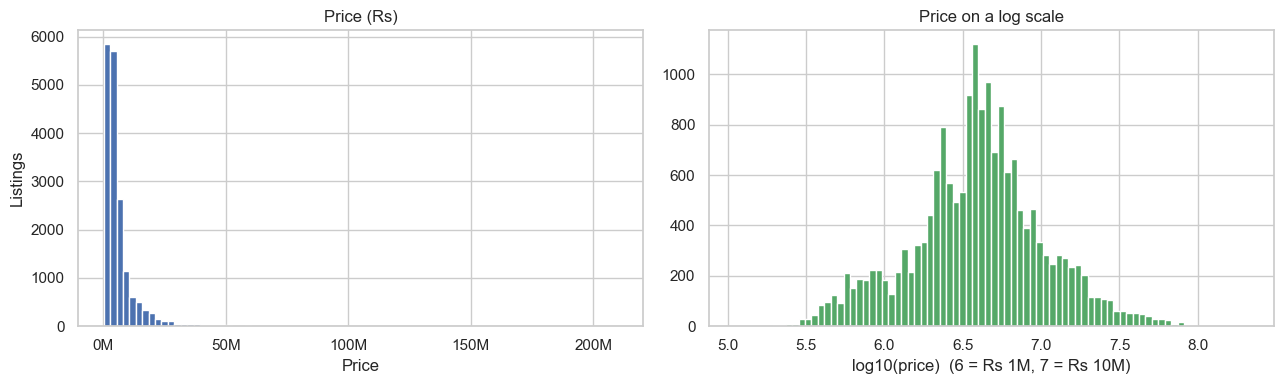

Mean   : Rs 6,367,734
Median : Rs 3,990,000
Skew   : raw 5.27 | log -0.03


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].hist(df["price"], bins=80, color="#4c72b0")
ax[0].xaxis.set_major_formatter(rs_millions)
ax[0].set(title="Price (Rs)", xlabel="Price", ylabel="Listings")
ax[1].hist(np.log10(df["price"]), bins=80, color="#55a868")
ax[1].set(title="Price on a log scale", xlabel="log10(price)  (6 = Rs 1M, 7 = Rs 10M)")
plt.tight_layout(); plt.show()

print(f"Mean   : Rs {df['price'].mean():,.0f}")
print(f"Median : Rs {df['price'].median():,.0f}")
print(f"Skew   : raw {df['price'].skew():.2f} | log {np.log(df['price']).skew():.2f}")

- Very right-skewed (skew 5.27): mean Rs 6.37M vs median Rs 3.99M
- On log scale it's almost symmetric (skew −0.03)
- → try training on log(price) (tested in 7.1)

### 4.2 How do year, mileage and engine size relate to price?

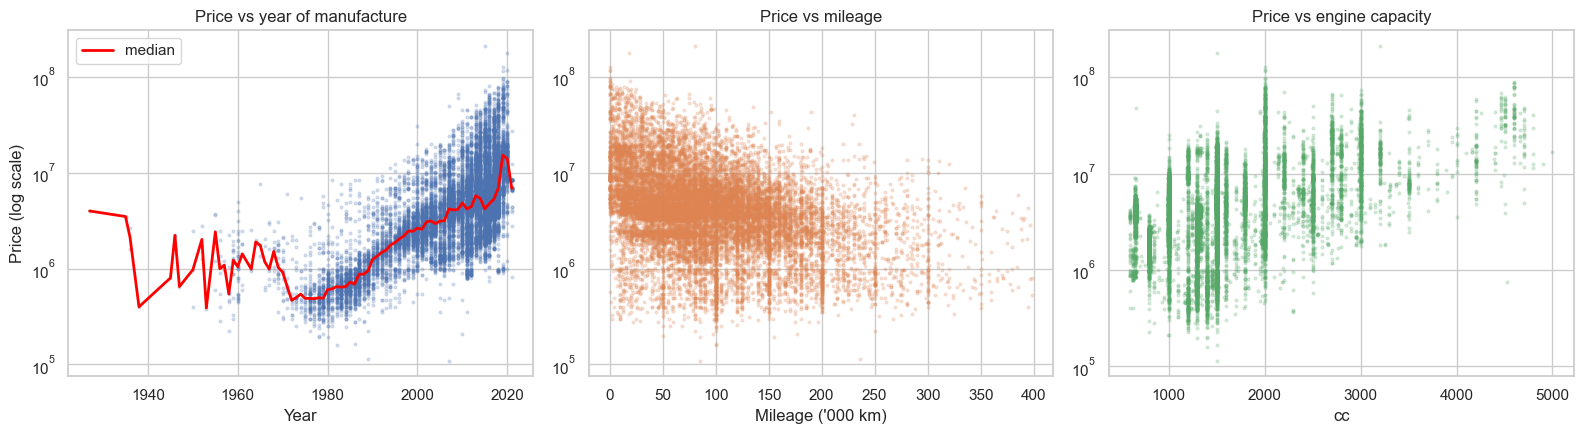

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
year_median = df.groupby("Year")["price"].median()
ax[0].scatter(df["Year"], df["price"], s=4, alpha=0.2)
ax[0].plot(year_median.index, year_median.values, color="red", lw=2, label="median")
ax[0].set(yscale="log", title="Price vs year of manufacture", xlabel="Year", ylabel="Price (log scale)")
ax[0].legend()

sample = df[df["mileage_km"] < 400_000]
ax[1].scatter(sample["mileage_km"] / 1000, sample["price"], s=4, alpha=0.2, color="#dd8452")
ax[1].set(yscale="log", title="Price vs mileage", xlabel="Mileage ('000 km)")

cc = df[(df["capacity_cc"] > 500) & (df["capacity_cc"] < 5000)]
ax[2].scatter(cc["capacity_cc"], cc["price"], s=4, alpha=0.2, color="#55a868")
ax[2].set(yscale="log", title="Price vs engine capacity", xlabel="cc")
plt.tight_layout(); plt.show()

- Newer cars cost more, but cars from before ~1980 go up again (classic cars)
- Higher mileage → lower price, but a lot of spread
- Bigger engine → higher price
- Relationships are not straight lines → tree models should do well

### 4.3 Which car types and brands are listed, and at what price?

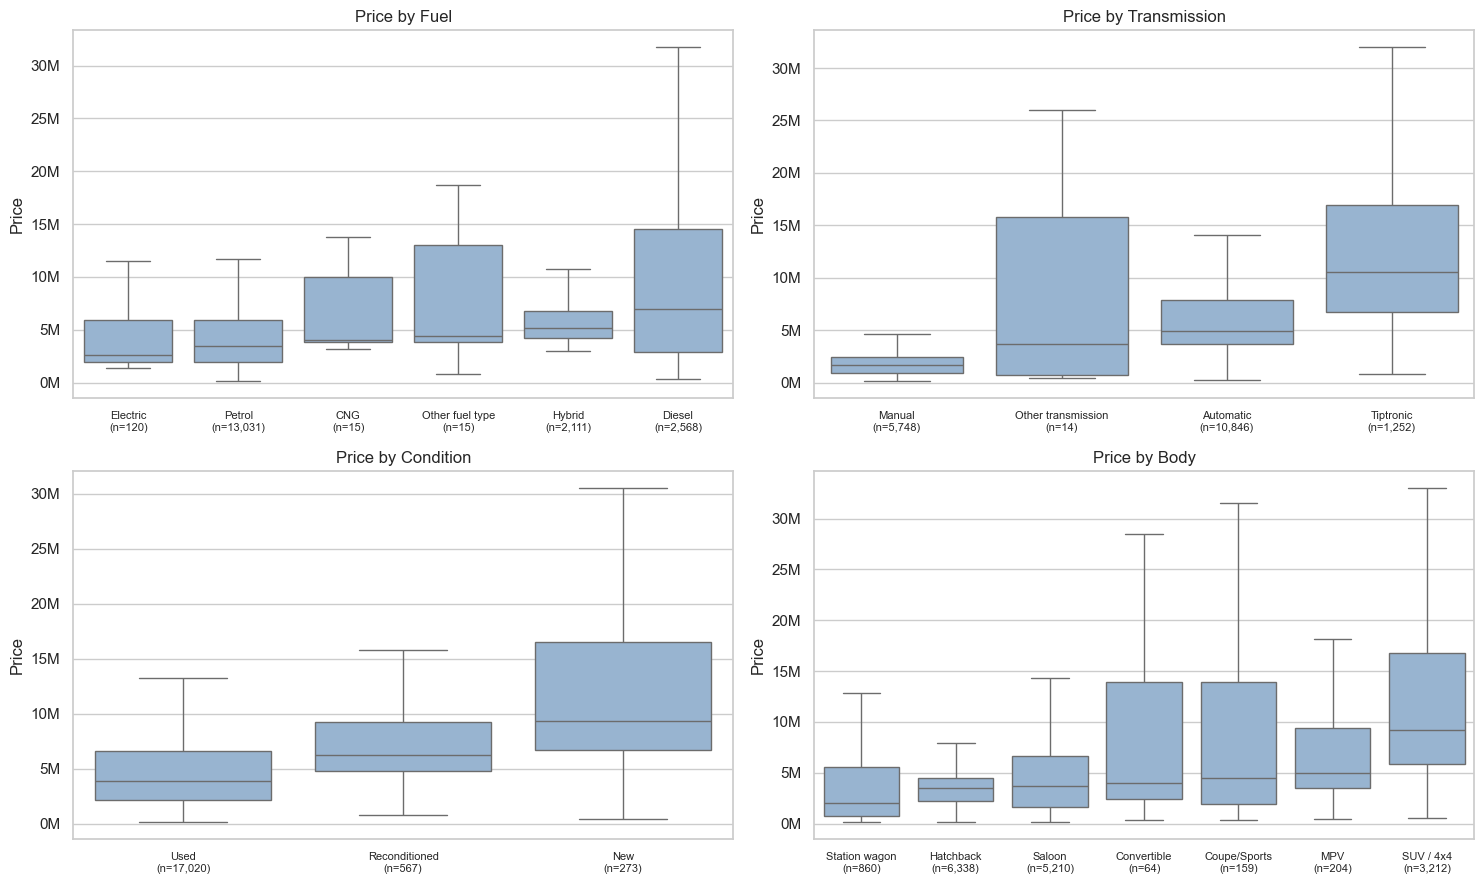

In [13]:
fig, ax = plt.subplots(2, 2, figsize=(15, 9))
for a, col in zip(ax.flat, ["Fuel", "Transmission", "Condition", "Body"]):
    order = df.groupby(col)["price"].median().sort_values().index
    sns.boxplot(data=df, x=col, y="price", order=order, ax=a, showfliers=False, color="#8fb4d9")
    a.yaxis.set_major_formatter(rs_millions)
    counts = df[col].value_counts()
    a.set_xticklabels([f"{t.get_text()}\n(n={counts[t.get_text()]:,})" for t in a.get_xticklabels()], fontsize=8)
    a.set(title=f"Price by {col}", xlabel="", ylabel="Price")
plt.tight_layout(); plt.show()

- Tiptronic/automatic cars cost more than manual (manual cars are mostly older)
- New > reconditioned > used
- SUVs are the most expensive body type
- Diesel has a wide range (cheap old vans to expensive SUVs/pickups)
- Electric, CNG and "Other transmission" have very few listings

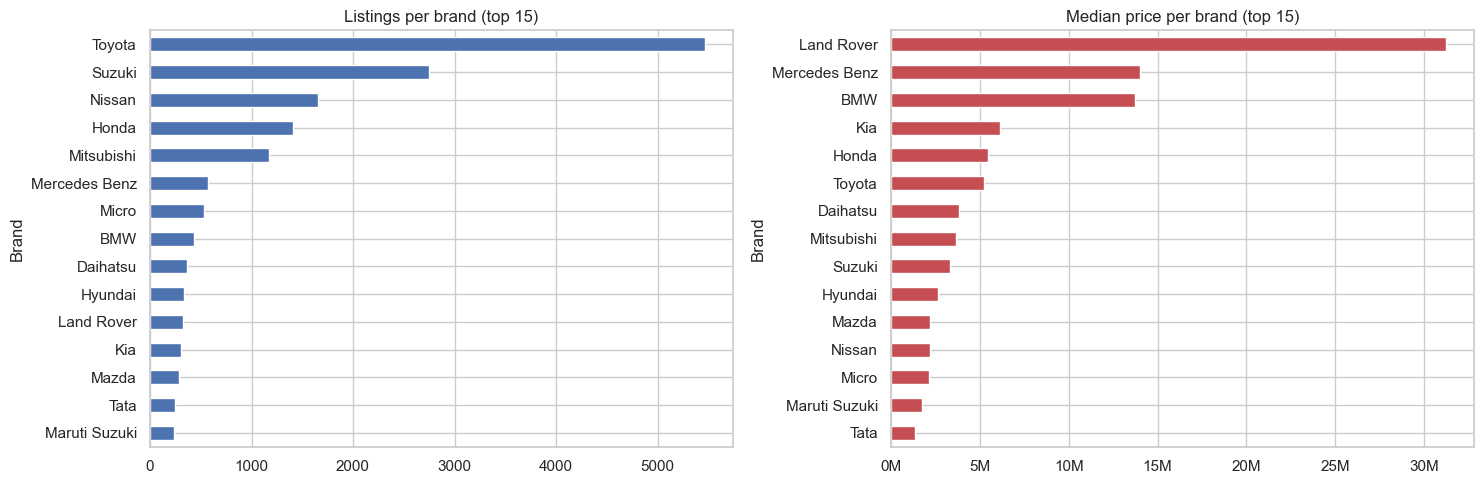

Brands: 57 | Models: 515
Models with fewer than 10 listings: 295


In [14]:
top_brands = df["Brand"].value_counts().head(15)
brand_price = df[df["Brand"].isin(top_brands.index)].groupby("Brand")["price"].median().loc[top_brands.index]

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
top_brands.sort_values().plot.barh(ax=ax[0], color="#4c72b0", title="Listings per brand (top 15)")
brand_price.sort_values().plot.barh(ax=ax[1], color="#c44e52", title="Median price per brand (top 15)")
ax[1].xaxis.set_major_formatter(rs_millions)
plt.tight_layout(); plt.show()

print("Brands:", df["Brand"].nunique(), "| Models:", df["Model"].nunique())
print("Models with fewer than 10 listings:", (df["Model"].value_counts() < 10).sum())

- Toyota and Suzuki dominate the listings
- Land Rover, Mercedes and BMW are much more expensive
- 515 models, 295 of them with fewer than 10 listings → rare models are grouped together in the encoder

### 4.4 Where are the cars listed?

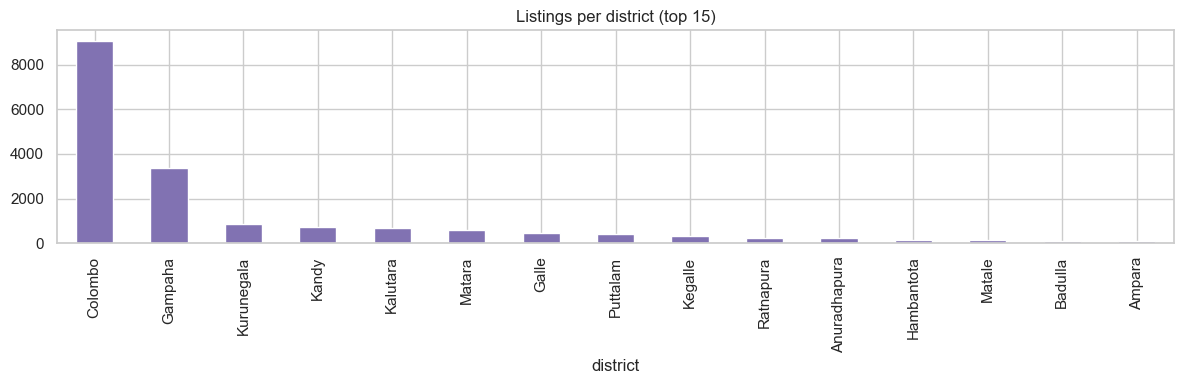

,listings,median_price
district,,
Colombo,9075,"4,650,000.00"
Gampaha,3362,"3,890,000.00"
Kurunegala,885,"2,650,000.00"
Kandy,733,"3,600,000.00"
Kalutara,687,"3,490,000.00"
Matara,579,"3,100,000.00"
Galle,460,"3,500,000.00"
Puttalam,407,"3,675,000.00"


In [15]:
district = df["Location"].str.split(",").str[-1].str.strip()
summary = (pd.DataFrame({"district": district, "price": df["price"]})
           .groupby("district")["price"].agg(listings="size", median_price="median")
           .sort_values("listings", ascending=False))
fig, ax = plt.subplots(figsize=(12, 4))
summary["listings"].head(15).plot.bar(ax=ax, color="#8172b2", title="Listings per district (top 15)")
plt.tight_layout(); plt.show()
display(summary.head(8))

Most listings are from Colombo (9,075) and Gampaha (3,362). Colombo has the highest median price (Rs 4.65M). Kept `district` as a feature.

### 4.5 Is missing body type random?

In [16]:
miss = df["Body"].isna()
print(f"Body missing: {miss.mean():.1%} of listings")
print(f"Median price with body known  : Rs {df.loc[~miss, 'price'].median():,.0f}")
print(f"Median price with body missing: Rs {df.loc[miss, 'price'].median():,.0f}")
display(df.assign(body_missing=miss).groupby("Brand")["body_missing"].agg(["mean", "size"])
        .query("size >= 200").sort_values("mean", ascending=False).head(8))

Body missing: 10.2% of listings
Median price with body known  : Rs 3,990,000
Median price with body missing: Rs 3,950,000


,mean,size
Brand,,
Micro,0.18,530
Suzuki,0.13,2745
Honda,0.12,1412
Daihatsu,0.11,362
Tata,0.10,245
Toyota,0.10,5470
Mitsubishi,0.10,1168
Hyundai,0.09,337


Median price is almost the same with or without Body (Rs 3.99M vs 3.95M), and it's missing across all brands (9–18%). Doesn't look like it follows a pattern, so a "Missing" category is fine (also tested in 7.1).

### 4.6 Correlation between numeric features

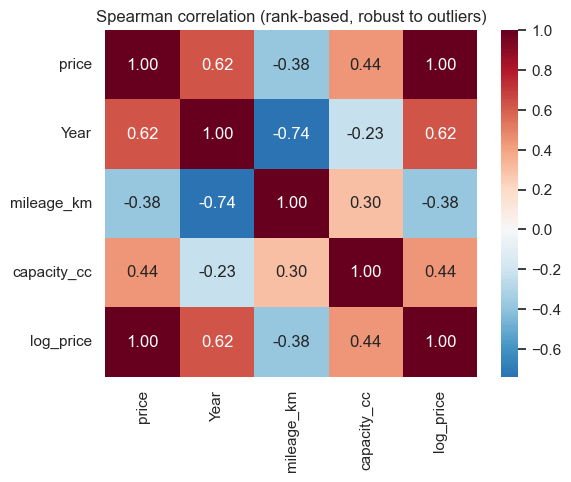

In [17]:
num = df[["price", "Year", "mileage_km", "capacity_cc"]].assign(log_price=np.log(df["price"]))
plt.figure(figsize=(6, 4.5))
sns.heatmap(num.corr(method="spearman"), annot=True, fmt=".2f", cmap="RdBu_r", center=0)
plt.title("Spearman correlation (rank-based, robust to outliers)")
plt.show()

- Year has the strongest link with price (0.62)
- Year and mileage are strongly linked (−0.74) – older cars have more km. Using `age` and `km_per_year` helps separate the two
- log_price gives the same values as price because Spearman only uses ranks

## 5) Feature engineering

New features:
- **age** = listing year − manufacture year
- **brand_model** e.g. "Toyota Aqua"
- **district** from location (25 districts instead of hundreds of towns)
- **unregistered** = title mentions "unregistered" (newly imported)
- **km_per_year** = mileage / age (added in Section 6)

Done before outlier handling because Section 6 needs `age` and `brand_model`.

In [18]:
def add_features(df):
    df = df.copy()
    posted_year = pd.to_datetime(df["published_date"]).dt.year if "published_date" in df else 2021
    df["age"] = (posted_year - df["Year"]).clip(lower=0)
    df["brand_model"] = df["Brand"].str.strip() + " " + df["Model"].str.strip()
    df["district"] = df["Location"].astype(str).str.split(",").str[-1].str.strip()
    df["unregistered"] = df["Title"].astype(str).str.contains("unregist", case=False).astype(int)
    return df

In [19]:
df = add_features(df)
display(df[["Title", "Year", "age", "brand_model", "district", "unregistered"]].head())
print("Unregistered listings:", df["unregistered"].sum())
display(df.groupby(["Condition", "unregistered"])["price"].agg(["size", "median"]))

,Title,Year,age,brand_model,district,unregistered
0,Micro Panda Auto 2019 for sale,2019,2,Micro Panda,Colombo,0
1,Toyota GT86 Company Maintained 2013 for sale,2013,8,Toyota GT86,Colombo,0
2,"Toyota IST FL , GRADE 2003 for sale",2003,18,Toyota IST,Puttalam,0
3,Toyota Allion 240 2002 for sale,2002,19,Toyota Allion,Kandy,0
4,Micro Panda LC 1.0 2015 for sale,2015,6,Micro Panda,Gampaha,0


Unregistered listings: 112


size        median
Condition     unregistered                     
New           0               246  9,325,000.00
              1                27 10,500,000.00
Reconditioned 0               487  6,200,000.00
              1                80  6,145,000.00
Used          0             17015  3,875,000.00
              1                 5 43,500,000.00

112 listings say "unregistered". New/reconditioned unregistered cars are priced a bit differently from registered ones. Only 5 used cars are unregistered, so this feature won't matter much.

## 6) Data errors & outliers

Extreme doesn't always mean wrong (e.g. a 1960 Mini), so each case is checked instead of just cutting the top/bottom %.

### 6.1 Engine capacity

In [20]:
ev = df["Fuel"].eq("Electric")
print("Petrol/diesel/hybrid cars with capacity below 10 cc:")
display(df[(~ev) & (df["capacity_cc"] < 10)][["Title", "Fuel", "capacity_cc"]].head(6))
print("Electric cars' 'capacity' values:", sorted(df.loc[ev, "capacity_cc"].unique())[:12])

Petrol/diesel/hybrid cars with capacity below 10 cc:


,Title,Fuel,capacity_cc
776,Toyota CHR GT 2017 for sale,Petrol,1
6797,Mercedes Benz E300 Bluetec 2014 for sale,Diesel,2
7972,Toyota Corolla DX wagon 1992 for sale,Diesel,2
8403,Toyota Hilux Revolution 2016 for sale,Diesel,2
12798,Honda Vezel 2014 for sale,Petrol,2
14045,Peugeot 5008 Active Upgraded 2018 for sale,Petrol,1


Electric cars' 'capacity' values: [np.int64(4), np.int64(40), np.int64(70), np.int64(75), np.int64(76), np.int64(80), np.int64(100), np.int64(110), np.int64(111), np.int64(125), np.int64(130), np.int64(132)]


- "1 cc"/"2 cc" on petrol/diesel cars = engine size typed in litres → ×1000
- Electric cars have values like 70 or 110 (probably kW or battery kWh, not cc) → set to 0, Fuel = Electric covers it
- Small values on cars that are normally 1000cc+ (e.g. a Corona at 145 cc) → set missing and imputed

In [21]:
def fix_capacity(df):
    df = df.copy()
    ev = df["Fuel"].eq("Electric")
    litres = (~ev) & (df["capacity_cc"] < 10)  # "2 cc" = 2.0L
    df.loc[litres, "capacity_cc"] *= 1000
    typical = df[~ev].groupby("brand_model")["capacity_cc"].transform("median")
    impossible = (~ev) & (df["capacity_cc"] < 600) & (typical >= 600)
    df.loc[impossible, "capacity_cc"] = np.nan
    df.loc[ev, "capacity_cc"] = 0  # no cc for EVs
    return df, {"litres_converted": int(litres.sum()), "set_missing": int(impossible.sum()),
                "electric_set_zero": int(ev.sum())}

In [22]:
df, cc_log = fix_capacity(df)
print(cc_log)

{'litres_converted': 16, 'set_missing': 20, 'electric_set_zero': 120}


### 6.2 Mileage

In [23]:
kmpy = df["mileage_km"] / df["age"].clip(lower=1)
display(df.assign(km_per_year=kmpy).nlargest(6, "km_per_year")[["Title", "Year", "mileage_km", "km_per_year"]])
print("Used cars listed with 0 km:", ((df["mileage_km"] == 0) & (df["Condition"] == "Used")).sum())

,Title,Year,mileage_km,km_per_year
5469,Daihatsu Atrai Wagon 2019 for sale,2019,380000,"190,000.00"
16028,Honda Vezel 2014 for sale,2014,1000000,"142,857.14"
6628,Mitsubishi Montero GLS 2015 for sale,2015,780000,"130,000.00"
14891,Honda Vezel 2014 for sale,2014,890000,"127,142.86"
7599,Suzuki Alto 2021 for sale,2021,114000,"114,000.00"
8049,Hyundai Tucson 2021 for sale,2021,112000,"112,000.00"


Used cars listed with 0 km: 3


A 2019 car with 380,000 km or a 2014 Vezel with 1,000,000 km isn't realistic. Above 80,000 km/year → set missing (imputed later). Also 3 used cars listed with 0 km.

In [24]:
MAX_KM_PER_YEAR = 80_000

def fix_mileage(df):
    df = df.copy()
    km_per_year = df["mileage_km"] / df["age"].clip(lower=1)
    bad = (km_per_year > MAX_KM_PER_YEAR) | ((df["mileage_km"] == 0) & (df["Condition"] == "Used"))
    df.loc[bad, "mileage_km"] = np.nan
    df["km_per_year"] = df["mileage_km"] / df["age"].clip(lower=1)
    return df, {"set_missing": int(bad.sum())}

{'set_missing': 17}


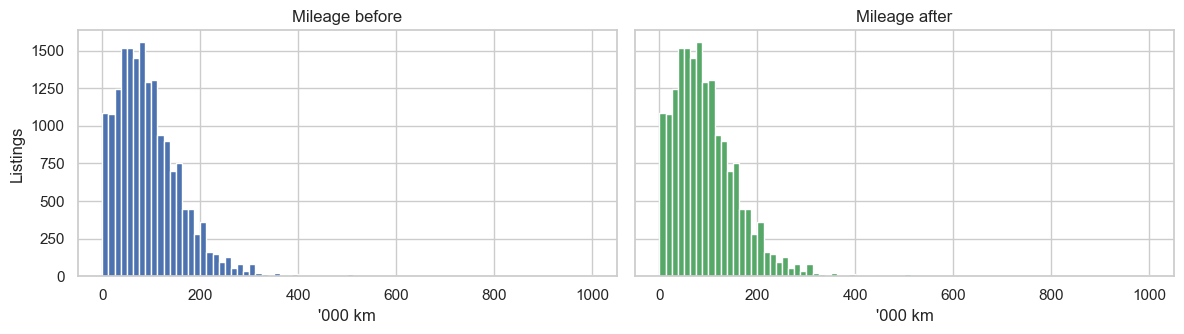

In [25]:
before = df["mileage_km"].copy()
df, mileage_log = fix_mileage(df)
print(mileage_log)

fig, ax = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
ax[0].hist(before / 1000, bins=80); ax[0].set(title="Mileage before", xlabel="'000 km", ylabel="Listings")
ax[1].hist(df["mileage_km"].dropna() / 1000, bins=80, color="#55a868"); ax[1].set(title="Mileage after", xlabel="'000 km")
plt.tight_layout(); plt.show()

### 6.3 Price outliers

Some prices look normal overall but are wrong for that car (e.g. 2020 Premio at Rs 179M – extra zero). Rule: drop a listing if it's more than 3x above/below the median for the same model + year (groups with 5+ listings).

This uses price, so medians are calculated on the training set only (after the split).

## 7) Train/test split + preprocessing pipeline

We will:
- Split 80/20 before anything that uses price
- Remove price outliers using train medians
- Pipeline: median impute + scale (numeric), "Missing" + one-hot (categorical, rare <10 grouped)
- Train on log(price) using `TransformedTargetRegressor`

Everything is inside the `Pipeline` so CV folds don't leak.

**Train / validation / test:** 80% train, 20% test (not touched until Section 10). Validation = cross-validation inside the training set: 5-fold to compare models, 3-fold for tuning.

In [26]:
from sklearn.model_selection import train_test_split

CAT_FEATURES = ["brand_model", "Brand", "Condition", "Transmission", "Body", "Fuel", "district"]
NUM_FEATURES = ["age", "mileage_km", "capacity_cc", "km_per_year", "unregistered"]
FEATURES = CAT_FEATURES + NUM_FEATURES
TARGET = "price"
OUTLIER_FACTOR, MIN_GROUP_SIZE = 3, 5

train_df, test_df = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", train_df.shape, "| Test:", test_df.shape)

Train: (14288, 18) | Test: (3572, 18)


In [27]:
def fit_price_reference(train_df):
    # only call this on the training set
    return (train_df.groupby(["brand_model", "Year"])["price"]
            .agg(group_median="median", group_size="size").reset_index())


def flag_price_outliers(df, reference):
    merged = df[["brand_model", "Year", "price"]].merge(reference, on=["brand_model", "Year"], how="left")
    ratio = np.abs(np.log(merged["price"] / merged["group_median"]))
    return ((merged["group_size"] >= MIN_GROUP_SIZE) & (ratio > np.log(OUTLIER_FACTOR))).to_numpy()

In [28]:
reference = fit_price_reference(train_df)
out_train = flag_price_outliers(train_df, reference)
out_test = flag_price_outliers(test_df, reference)
print(f"Flagged: {out_train.sum()} train, {out_test.sum()} test")

flagged = train_df[out_train].merge(reference, on=["brand_model", "Year"])
display(flagged.assign(times_median=flagged["price"] / flagged["group_median"])
        [["brand_model", "Year", "price", "group_median", "times_median"]]
        .sort_values("times_median").round(2))

train_df, test_df = train_df[~out_train], test_df[~out_test]
X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]
print("Final train:", X_train.shape, "| Final test:", X_test.shape)

Flagged: 23 train, 2 test


,brand_model,Year,price,group_median,times_median
16,Nissan Sunny,1989,115000,"1,150,000.00",0.10
0,Suzuki Alto,2010,210000,"1,830,000.00",0.11
19,Nissan Sunny,2001,550000,"2,775,000.00",0.20
15,Mitsubishi Outlander,2016,3000000,"12,250,000.00",0.24
7,Nissan Sunny,1992,350000,"1,425,000.00",0.25
20,Toyota Corolla,1992,370000,"1,495,000.00",0.25
2,Mitsubishi Lancer,1997,575000,"2,287,500.00",0.25
6,Toyota Allion,2007,1450000,"5,387,500.00",0.27
17,Toyota Corolla,1989,350000,"1,192,500.00",0.29
1,Nissan Sunny,1982,160000,"500,000.00",0.32


Final train: (14265, 12) | Final test: (3570, 12)


25 listings removed (23 train, 2 test). Examples: 2020 Premio at Rs 179M (9x median), 2014 Aqua at Rs 45M (9.8x). Some might be genuine (e.g. a restored 1960 Mini Cooper at Rs 5M), but it's only 0.14% of the data.

Body is missing in 1,460 training rows; mileage/capacity in a few – handled by the pipeline. 12 input columns → 304 after one-hot encoding.

In [29]:
def build_preprocessor(cat_impute="constant"):
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([
        ("impute", SimpleImputer(strategy="constant", fill_value="Missing") if cat_impute == "constant"
         else SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10))])
    return ColumnTransformer([("num", numeric, NUM_FEATURES), ("cat", categorical, CAT_FEATURES)])


def make_pipeline(estimator, log_target=True, cat_impute="constant"):
    pipe = Pipeline([("preprocess", build_preprocessor(cat_impute)), ("model", estimator)])
    if log_target:
        return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)
    return pipe

In [30]:
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

pre = build_preprocessor().fit(X_train)
print("Input columns:", len(FEATURES), "-> columns after encoding:", len(pre.get_feature_names_out()))
print("Missing values in training data:")
print(X_train.isna().sum()[lambda s: s > 0])

Input columns: 12 -> columns after encoding: 304
Missing values in training data:
Body           1460
mileage_km       12
capacity_cc      16
km_per_year      12
dtype: int64


### 7.1 Preprocessing experiments

Testing two choices with 5-fold CV:
1. raw price vs log(price)
2. "Missing" category vs most frequent value for missing categories

In [ ]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.linear_model import Ridge
from lightgbm import LGBMRegressor

cv5 = KFold(5, shuffle=True, random_state=RANDOM_STATE)
SCORING = {"mae": "neg_mean_absolute_error", "r2": "r2", "mape": "neg_mean_absolute_percentage_error"}

def cv_score(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv5, scoring=SCORING)
    return {"CV MAE (Rs)": -r["test_mae"].mean(), "CV R2": r["test_r2"].mean(), "CV MAPE": -r["test_mape"].mean()}

lgbm = lambda: LGBMRegressor(n_estimators=400, learning_rate=0.05, random_state=RANDOM_STATE, verbose=-1)
experiments = {
    "Ridge | raw price":            make_pipeline(Ridge(), log_target=False),
    "Ridge | log price":            make_pipeline(Ridge(), log_target=True),
    "LightGBM | raw price":         make_pipeline(lgbm(), log_target=False),
    "LightGBM | log price":         make_pipeline(lgbm(), log_target=True),
    "LightGBM | log | most-frequent fill": make_pipeline(lgbm(), log_target=True, cat_impute="most_frequent"),
}
exp_results = pd.DataFrame({k: cv_score(v) for k, v in experiments.items()}).T
display(exp_results.style.format({"CV MAE (Rs)": "{:,.0f}", "CV R2": "{:.3f}", "CV MAPE": "{:.1%}"}))

- **Log target helps a lot for Ridge**: MAE Rs 1.80M → 1.13M, MAPE 58% → 18%
- **For LightGBM too**: MAE Rs 945k → 914k, MAPE 17.6% → 14.3%
- Missing vs most-frequent fill: almost no difference (914,407 vs 913,953) → kept "Missing" since it doesn't assume a body type

→ log(price) + "Missing" category used for all models.

## 8) New algorithm (LightGBM) vs benchmark models

### 8.1 Why LightGBM

LightGBM (Microsoft, 2017) is a gradient boosting method built for large tabular data. It was not covered in lectures.

| | How LightGBM differs |
|---|---|
| Decision Tree | one tree vs hundreds of small trees, each fixing the errors of the previous ones |
| Random Forest | trees built **one after another** (boosting) instead of independently and averaged (bagging) |
| XGBoost | trees grow **leaf-wise** (splits the leaf with the biggest error) instead of level-wise; features are binned into **histograms**, so it trains much faster |
| Linear Regression | captures non-linear effects and interactions without adding them by hand |
| KNN | learns rules from all the data instead of copying nearby cars |

Why it suits this data:
- EDA showed non-linear effects (age, classic cars, engine size)
- 304 columns after one-hot encoding – histogram binning handles this efficiently
- Fast on 14k rows, so tuning is cheap
- Tree-based → exact SHAP values with `TreeExplainer`

### 8.2 Comparison with benchmarks

Same pipeline for all, compared with 5-fold CV on train:
- **MAE** (Rs) – main metric
- **R²**
- **MAPE** (% error)

In [ ]:
NEW_ALGORITHM = "LightGBM"
COVERED_IN_LECTURES = {"LinearRegression", "Ridge", "DecisionTree", "RandomForest", "SVR", "XGBoost"}

def model_type(name):
    if name == NEW_ALGORITHM:
        return "New algorithm"
    if name.startswith("Baseline"):
        return "Baseline"
    return "Benchmark (covered)" if name in COVERED_IN_LECTURES else "Benchmark"


def candidate_estimators(random_state=RANDOM_STATE):
    return {
        "Baseline (median)": DummyRegressor(strategy="median"),
        "LinearRegression": LinearRegression(),
        "Ridge": Ridge(random_state=random_state),
        "KNN": KNeighborsRegressor(n_neighbors=10),
        "DecisionTree": DecisionTreeRegressor(random_state=random_state),
        "RandomForest": RandomForestRegressor(n_estimators=150, max_features=0.3, min_samples_leaf=2,
                                              random_state=random_state, n_jobs=-1),
        "SVR": SVR(),
        "XGBoost": XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6,
                                random_state=random_state, n_jobs=-1),
        "LightGBM": LGBMRegressor(n_estimators=400, learning_rate=0.05,
                                  random_state=random_state, verbose=-1),
    }

from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor

In [ ]:
import time

results = []
for name, est in candidate_estimators(RANDOM_STATE).items():
    start = time.time()
    scores = cv_score(make_pipeline(est))
    results.append({"model": name, "type": model_type(name), **scores, "train time (s)": time.time() - start})
    print(f"{name:<18} done in {time.time() - start:5.1f}s")

results = pd.DataFrame(results).sort_values("CV MAE (Rs)").reset_index(drop=True)
display(results.style.format({"CV MAE (Rs)": "{:,.0f}", "CV R2": "{:.3f}", "CV MAPE": "{:.1%}",
                              "train time (s)": "{:.1f}"}))

In [ ]:
plot = results[results["model"] != "Baseline (median)"].sort_values("CV MAE (Rs)", ascending=False)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].barh(plot["model"], plot["CV MAE (Rs)"], color="#4c72b0")
ax[0].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
ax[0].set(title="Average error (MAE, Rs) — lower is better")
ax[1].barh(plot["model"], plot["CV MAPE"], color="#dd8452")
ax[1].xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax[1].set(title="Average % error (MAPE) — lower is better")
plt.tight_layout(); plt.show()
print(f"Baseline MAE: Rs {results.loc[results.model == 'Baseline (median)', 'CV MAE (Rs)'].iloc[0]:,.0f}")

- All models beat the baseline by far (baseline MAE Rs 4.09M)
- **LightGBM (new algorithm): Rs 914k** – in the top 4 with SVR (891k), Random Forest (913k) and XGBoost (926k)
- Linear models and KNN are clearly worse (~Rs 1.1M+), which matches the non-linear patterns in EDA
- LightGBM trains in ~4 s for 5 folds vs 103 s for Random Forest

Tuned next: LightGBM + the 2 strongest benchmarks (SVR, Random Forest).

## 9) Hyperparameter tuning

Tune the new algorithm (LightGBM) and the 2 strongest benchmarks from Section 8, so the comparison is fair. `RandomizedSearchCV` (12 settings, 3-fold CV, MAE). Defaults are scored on the same folds and kept if tuning doesn't beat them.

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import loguniform, randint, uniform

P = "regressor__model__"
SEARCH_SPACES = {
    "Ridge": {P + "alpha": loguniform(0.01, 100)},
        "KNN": {P + "n_neighbors": randint(3, 30), P + "weights": ["uniform", "distance"]},
        "DecisionTree": {P + "max_depth": [None, 10, 15, 20, 30], P + "min_samples_leaf": randint(1, 20)},
        "RandomForest": {P + "n_estimators": [100, 150, 200], P + "max_features": [0.2, 0.3, 0.5],
                         P + "min_samples_leaf": [1, 2, 4], P + "max_depth": [None, 20, 30]},
        "SVR": {P + "C": loguniform(1, 100), P + "gamma": ["scale", 0.01, 0.03, 0.1],
                P + "epsilon": [0.01, 0.05, 0.1]},
        "XGBoost": {P + "n_estimators": randint(300, 1500), P + "learning_rate": loguniform(0.02, 0.15),
                    P + "max_depth": randint(3, 10), P + "min_child_weight": randint(1, 10),
                    P + "subsample": uniform(0.7, 0.3), P + "colsample_bytree": uniform(0.5, 0.5),
                    P + "reg_lambda": loguniform(0.1, 10)},
        "LightGBM": {P + "n_estimators": randint(300, 1500), P + "learning_rate": loguniform(0.02, 0.15),
                     P + "num_leaves": randint(15, 128), P + "min_child_samples": randint(5, 50),
                     P + "subsample": uniform(0.7, 0.3), P + "subsample_freq": [1],
                     P + "colsample_bytree": uniform(0.5, 0.5), P + "reg_lambda": loguniform(0.1, 10)},
}

In [ ]:
TOP_K, N_ITER = 3, 12
cv3 = KFold(3, shuffle=True, random_state=RANDOM_STATE)
benchmarks = results.loc[~results["model"].isin(["Baseline (median)", NEW_ALGORITHM]), "model"].head(TOP_K - 1).tolist()
top_models = [NEW_ALGORITHM] + benchmarks
print("Tuning:", top_models)

tuned, tuning_rows = {}, []
for name in top_models:
    start = time.time()
    est = candidate_estimators(RANDOM_STATE)[name]
    search = RandomizedSearchCV(make_pipeline(est), SEARCH_SPACES[name], n_iter=N_ITER, cv=cv3,
                                scoring="neg_mean_absolute_error", random_state=RANDOM_STATE)
    search.fit(X_train, y_train)
    default_mae = -cross_validate(make_pipeline(est), X_train, y_train, cv=cv3,
                                  scoring="neg_mean_absolute_error")["test_score"].mean()
    tuned_mae = -search.best_score_
    if tuned_mae < default_mae:
        tuned[name] = {"model": search.best_estimator_, "cv_mae": tuned_mae,
                       "params": search.best_params_, "used": "tuned"}
    else:
        tuned[name] = {"model": make_pipeline(est).fit(X_train, y_train), "cv_mae": default_mae,
                       "params": {}, "used": "default"}
    tuning_rows.append({"model": name, "default CV MAE": default_mae, "tuned CV MAE": tuned_mae,
                        "improvement": 1 - tuned_mae / default_mae, "kept": tuned[name]["used"],
                        "minutes": (time.time() - start) / 60})

tuning = pd.DataFrame(tuning_rows)
display(tuning.style.format({"default CV MAE": "{:,.0f}", "tuned CV MAE": "{:,.0f}",
                             "improvement": "{:+.1%}", "minutes": "{:.1f}"}))
for name, t in tuned.items():
    print(f"\n{name} best settings:", {k.replace(P, ''): (round(v, 4) if isinstance(v, float) else v)
                                         for k, v in t["params"].items()} or "defaults kept")

Tuning improved all three (on the same 3 folds):
- **LightGBM: Rs 931k → 850k (−8.7%)**, only 1.7 min
- SVR: Rs 920k → 858k (−6.6%), 8.4 min
- Random Forest: Rs 935k → 877k (−6.3%), 10 min

After tuning, LightGBM has the lowest error of the three. Its best settings use more trees (1,321) with smaller trees (20 leaves).

## 10) Final evaluation & model selection

LightGBM is the selected new algorithm. Check where it ranks against the tuned benchmarks, then test it on the test set (not used so far).

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, mean_absolute_percentage_error

best_name = NEW_ALGORITHM
rank = sorted(tuned, key=lambda n: tuned[n]["cv_mae"]).index(best_name) + 1
print(f"{best_name} tuned CV MAE rank: {rank} of {len(tuned)}")
best_model = tuned[best_name]["model"]
print("Selected model:", best_name, f"({tuned[best_name]['used']} settings)")

rows = []
for name, t in tuned.items():
    p = t["model"].predict(X_test)
    rows.append({"model": name, "test MAE (Rs)": mean_absolute_error(y_test, p),
                 "test RMSE (Rs)": np.sqrt(mean_squared_error(y_test, p)), "test R2": r2_score(y_test, p),
                 "test MAPE": mean_absolute_percentage_error(y_test, p),
                 "median % error": np.median(np.abs(p - y_test) / y_test)})
test_results = pd.DataFrame(rows).sort_values("test MAE (Rs)")
display(test_results.style.format({"test MAE (Rs)": "{:,.0f}", "test RMSE (Rs)": "{:,.0f}", "test R2": "{:.3f}",
                                   "test MAPE": "{:.1%}", "median % error": "{:.1%}"}))
pred = best_model.predict(X_test)

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(y_test, pred, s=5, alpha=0.3)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--", label="perfect prediction")
ax[0].set(xscale="log", yscale="log", xlabel="Actual price", ylabel="Predicted price",
          title=f"{best_name}: actual vs predicted (test set)")
ax[0].legend()

pct_err = (pred - y_test) / y_test
ax[1].scatter(y_test, pct_err, s=5, alpha=0.3, color="#dd8452")
ax[1].axhline(0, color="red", ls="--")
ax[1].set(xscale="log", ylim=(-1, 1.5), xlabel="Actual price", ylabel="Error (% of actual)",
          title="Residuals: over- and under-prediction")
ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
plt.tight_layout(); plt.show()

In [ ]:
bands = pd.cut(y_test, [0, 1e6, 2.5e6, 5e6, 10e6, 25e6, np.inf],
               labels=["< 1M", "1–2.5M", "2.5–5M", "5–10M", "10–25M", "> 25M"])
by_band = (pd.DataFrame({"band": bands, "abs_err": np.abs(pred - y_test), "pct_err": np.abs(pct_err)})
           .groupby("band", observed=True)
           .agg(listings=("abs_err", "size"), MAE_Rs=("abs_err", "mean"), median_pct_error=("pct_err", "median")))
display(by_band.style.format({"MAE_Rs": "{:,.0f}", "median_pct_error": "{:.1%}"}))

worst = test_df.assign(predicted=pred, pct_error=pct_err).reindex(pct_err.abs().sort_values(ascending=False).index)
print("Largest % errors:")
display(worst.head(6)[["Title", "Year", "mileage_km", "price", "predicted", "pct_error"]])

**Selected: LightGBM (tuned)** – the new algorithm, and it ranks 1st of the 3 tuned models on CV.

On the test set it's also the best: **MAE Rs 866k, R² 0.938, median error 8.8%**. SVR is close (Rs 873k) but slower and can't use TreeExplainer.

- Predictions follow the actual prices closely on the log plot
- Most accurate between Rs 1M–10M (median error 7–9%), where most cars are
- Weaker for cars under Rs 1M (18%) and over Rs 25M (14%) – fewer listings
- Biggest errors are unusual vehicles: a motorbike (Pioneer XL), an electric Mahindra e2o, a 1958 Austin – rare types the model hasn't seen much

MAE (Rs 866k) is higher than the median error because expensive cars have big rupee errors; RMSE (Rs 2.1M) shows the same.

## 11) SHAP explanations (global + local)

`TreeExplainer` on the best tree model. Model predicts log(price), so SHAP +0.10 ≈ +10.5% price. One-hot columns are summed back to the original feature.

In [ ]:
import shap

TREE_MODELS = ["DecisionTree", "RandomForest", "XGBoost", "LightGBM"]
shap_name = best_name if best_name in TREE_MODELS else min(
    [n for n in tuned if n in TREE_MODELS], key=lambda n: tuned[n]["cv_mae"])
shap_pipe = tuned[shap_name]["model"].regressor_          # fitted Pipeline (learns log price)
print("Explaining:", shap_name)

prep, est = shap_pipe.named_steps["preprocess"], shap_pipe.named_steps["model"]
X_sample = X_test.sample(1000, random_state=RANDOM_STATE)
X_trans = prep.transform(X_sample)
X_trans = X_trans.toarray() if hasattr(X_trans, "toarray") else X_trans
feature_names = [n.split("__", 1)[1] for n in prep.get_feature_names_out()]

explainer = shap.TreeExplainer(est)
shap_values = explainer.shap_values(X_trans)

# sum one-hot columns back to original feature
def original_feature(name):
    for c in sorted(CAT_FEATURES, key=len, reverse=True):
        if name.startswith(c + "_"):
            return c
    return name
groups = pd.Series([original_feature(n) for n in feature_names])
shap_grouped = pd.DataFrame(shap_values, columns=feature_names).T.groupby(groups.values).sum().T

In [ ]:
importance = shap_grouped.abs().mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(importance.index, importance.values, color="#4c72b0")
ax.set(title="Global importance: mean |SHAP| per original feature", xlabel="mean |SHAP| (log-price units)")
plt.tight_layout(); plt.show()
print((np.exp(importance.sort_values(ascending=False)) - 1).map("{:.0%}".format)
      .rename("typical price swing").to_frame().T)

**Age** is the most important feature by far (typical effect ~43% of price), then **engine capacity** (24%), **transmission** (23%) and **brand** (13%). District, condition and unregistered barely matter once these are known.

In [ ]:
shap.summary_plot(shap_values, X_trans, feature_names=feature_names, max_display=15, show=False)
plt.title("SHAP beeswarm: top 15 encoded features (red = high value, blue = low)")
plt.tight_layout(); plt.show()

- Low age (blue) → pushes price up, high age (red) → down
- Bigger engine → higher price
- Manual transmission → lower price
- Luxury brands (Mercedes, Land Rover, BMW) and Land Cruiser Prado push price up; Micro pushes down

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a, feat in zip(ax, ["age", "mileage_km"]):
    j = feature_names.index(feat)
    a.scatter(X_sample[feat], shap_values[:, j], s=6, alpha=0.4)
    a.axhline(0, color="grey", lw=1)
    a.set(xlabel=feat, ylabel="SHAP value (log price)", title=f"How {feat} changes the prediction")
ax[1].set_xlim(0, 300_000)
plt.tight_layout(); plt.show()

- Price drops fast in the first ~10 years, then levels off. After ~40 years it goes up a little (classic cars)
- Mileage effect is smaller: drops quickly up to ~100,000 km then flattens

In [ ]:
# local explanation - a mid-priced car
car_idx = int(np.argsort(np.abs(X_sample.index.map(y_test) - y_test.median()))[0])
car = X_sample.iloc[car_idx]
print("Car:", car[["brand_model", "age", "mileage_km", "Fuel", "Condition"]].to_dict())
print(f"Actual price Rs {y_test.loc[X_sample.index[car_idx]]:,.0f} | predicted Rs {np.expm1(explainer.expected_value + shap_values[car_idx].sum()):,.0f}")

local = shap_grouped.iloc[car_idx]
shap.plots.waterfall(shap.Explanation(values=local.values, base_values=float(explainer.expected_value),
                                      data=[str(car[f]) if f in car else "" for f in local.index],
                                      feature_names=list(local.index)), max_display=12)

Suzuki Wagon R Stingray, 3 years old, 44,000 km: predicted Rs 4.35M vs actual Rs 4.10M (6% off).
Young age adds the most (+0.41 ≈ +51%), but the small 650 cc engine pulls it down almost as much (−0.39). Automatic adds +0.18.

## 12) LIME explanation (local surrogate)

LIME works with any model and explains in Rs. Categories are coded as integers for LIME and decoded before predicting.

In [ ]:
from lime.lime_tabular import LimeTabularExplainer

categories = {c: sorted(X_train[c].dropna().astype(str).unique()) for c in CAT_FEATURES}

def encode(X):
    X = X.copy()
    for c in CAT_FEATURES:
        X[c] = X[c].astype(str).map({v: i for i, v in enumerate(categories[c])}).fillna(-1)
    return X.fillna(X_train[NUM_FEATURES].median())

def lime_predict(arr):
    X = pd.DataFrame(arr, columns=FEATURES)
    for c in CAT_FEATURES:
        idx = np.clip(np.rint(X[c].astype(float)).astype(int), 0, len(categories[c]) - 1)
        X[c] = [categories[c][i] for i in idx]
    return best_model.predict(X)

lime_explainer = LimeTabularExplainer(
    encode(X_train.sample(3000, random_state=RANDOM_STATE))[FEATURES].to_numpy(dtype=float),
    feature_names=FEATURES, mode="regression",
    categorical_features=[FEATURES.index(c) for c in CAT_FEATURES],
    categorical_names={FEATURES.index(c): categories[c] for c in CAT_FEATURES},
    discretize_continuous=True, random_state=RANDOM_STATE)

In [ ]:
# same car as SHAP + a budget car + a premium car
idx_shap = X_sample.index[car_idx]
idx_cheap = y_test[(y_test > 1.2e6) & (y_test < 1.8e6)].index[0]
idx_premium = y_test[(y_test > 12e6) & (y_test < 20e6)].index[0]

lime_tables = {}
for label, i in [("Mid-priced (same as SHAP)", idx_shap), ("Budget", idx_cheap), ("Premium", idx_premium)]:
    row = X_test.loc[[i]]
    exp = lime_explainer.explain_instance(encode(row)[FEATURES].to_numpy(dtype=float)[0], lime_predict,
                                          num_features=8, num_samples=3000)
    print(f"\n{label}: {row['brand_model'].iloc[0]}, age {row['age'].iloc[0]}, "
          f"{row['mileage_km'].iloc[0]:,.0f} km | actual Rs {y_test.loc[i]:,.0f} | "
          f"predicted Rs {best_model.predict(row)[0]:,.0f}")
    items = exp.as_list()[::-1]
    lime_tables[label] = exp.as_list()
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.barh([k for k, _ in items], [v for _, v in items],
            color=["#2e7d32" if v > 0 else "#c62828" for _, v in items])
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:+.1f}M"))
    ax.set(title=f"LIME — {label}", xlabel="Effect on price (Rs)")
    plt.tight_layout(); plt.show()

- **Mid-priced (Wagon R)**: young age adds ~Rs 3M, small engine takes off ~Rs 2M – same story as SHAP
- **Budget (Peugeot 406, 23 years)**: age takes off the most; the 1,800+ cc diesel engine adds value back. Predicted Rs 1.56M vs actual Rs 1.48M
- **Premium (BMW X1, 3 years)**: young age and BMW brand add the most. Predicted Rs 14.8M vs actual Rs 18.5M – underestimated by ~20%, which matches the higher error for expensive cars in Section 10

In [ ]:
# SHAP vs LIME top features for the same car
shap_rank = shap_grouped.iloc[car_idx].abs().sort_values(ascending=False).head(6)
lime_rank = pd.Series({k: abs(v) for k, v in lime_tables["Mid-priced (same as SHAP)"]})
lime_features = [next((f for f in sorted(FEATURES, key=len, reverse=True) if f in k), k) for k in lime_rank.index]
compare = pd.DataFrame({"SHAP top features": shap_rank.index,
                        "LIME top features": (lime_features + [""] * 6)[:6]})
display(compare)
print("Features in both top-6 lists:", sorted(set(shap_rank.index) & set(lime_features[:6])))

5 of the top 6 features are the same (age, capacity, transmission, brand, mileage), with the same top 3 in the same order. The two methods agree, so the explanations look reliable.

## 13) Interpreting the predictions

What drives used car prices in this data:
1. **Age** – biggest factor; most value is lost in the first ~10 years
2. **Engine size** – small kei cars (660 cc) are much cheaper than 1,500cc+ cars of the same age
3. **Transmission** – manual cars are cheaper (mostly older/basic cars)
4. **Brand / model** – luxury brands and models like the Land Cruiser Prado hold high prices
5. **Mileage** – matters, but less than age

Local context: this data is from 2021, when vehicle imports were restricted in Sri Lanka. Supply was limited, so used cars (even older ones) were priced high. The model reflects that market, not today's.

For a buyer: if a listing is well above the typical range, it's worth questioning the price.

### 13.1 Partial dependence (PDP)

Average predicted price when one feature changes and everything else stays the same.

In [ ]:
from sklearn.inspection import PartialDependenceDisplay

X_pdp = train_df[FEATURES].sample(1500, random_state=RANDOM_STATE).astype({c: float for c in NUM_FEATURES})
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
PartialDependenceDisplay.from_estimator(best_model, X_pdp, ["age", "mileage_km", "capacity_cc"], kind="average",
                                        percentiles=(0.02, 0.98), grid_resolution=25, ax=ax)
for a in ax:
    a.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1e6:.1f}M"))
plt.tight_layout(); plt.show()

- **Age:** average price falls from ~Rs 8.9M at 2 years to ~Rs 4.7M at 12 years and ~Rs 1.1M at 43 years – steepest in the early years
- **Mileage:** Rs 7.1M at ~5,000 km to Rs 4.4M at 300,000 km – a smaller effect that flattens after ~150,000 km
- **Engine size:** Rs 3.5M at 650 cc to Rs 9.8M at 3,200 cc

Same story as SHAP, from a different method.

### 13.2 Does the model match domain knowledge?

| Model learned | Expected from the car market | Match |
|---|---|---|
| Price drops fast in the first ~10 years, then levels off | Cars lose most value early | ✓ |
| Very old cars (40+ years) rise slightly | Vintage/classic cars are collectable | ✓ |
| Bigger engine → higher price | Larger, more powerful cars cost more | ✓ |
| Manual cheaper than automatic | Newer imports are mostly automatic | ✓ |
| Luxury brands and the Prado priced higher | Brand value | ✓ |
| District hardly matters | Cars are advertised and sold island-wide online | ✓ |

### 13.3 Bias check – is the error similar across groups?

Median % error (accuracy) and median signed error (+ = over-predicts, − = under-predicts) on the test set.

In [ ]:
err = pd.DataFrame({"abs_pct": np.abs(pred - y_test) / y_test, "signed_pct": (pred - y_test) / y_test,
                    "district": test_df["district"], "Fuel": test_df["Fuel"], "Condition": test_df["Condition"],
                    "brand_listings": test_df["Brand"].map(train_df["Brand"].value_counts()).fillna(0)})
err["area"] = np.where(err["district"].isin(["Colombo", "Gampaha"]), err["district"], "Other districts")
err["brand_group"] = np.where(err["brand_listings"] >= 200, "Common brand (200+ listings)", "Rare brand (<200)")

def summary(col):
    return (err.groupby(col).agg(listings=("abs_pct", "size"), median_error=("abs_pct", "median"),
                                 median_bias=("signed_pct", "median"))
            .sort_values("listings", ascending=False))

for col in ["area", "brand_group", "Fuel", "Condition"]:
    display(summary(col).style.format({"median_error": "{:.1%}", "median_bias": "{:+.1%}"}))

- **Location:** median error Colombo 8.4%, Gampaha 9.0%, other districts 9.2% – similar, so cars outside Colombo aren't treated much worse
- **Brand:** rare brands 9.6% vs common brands 8.7% – slightly worse, fewer examples to learn from
- **Fuel:** diesel 12.6% and electric 12.2% (only 28 cars) vs petrol 8.2% and hybrid 7.8%
- **Condition:** reconditioned 10.4% vs used 8.8%
- **Direction:** median bias is within ±2.6% for the main groups – no group is systematically over- or under-priced. EVs are over-predicted (+8.4%) but there are only 28 in the test set

Combined with Section 10: cheap cars (<Rs 1M, 18.3%) and expensive cars (>Rs 25M) have bigger errors, and expensive cars tend to be under-estimated.

## 14) Save & reload the model

Save the full pipeline with joblib (pickle-based) + `metadata.json` (metrics, app dropdown options, fair range). Reload and check predictions match.

In [ ]:
import joblib, json
from src.train import save_artifacts

cfg = {"artifacts_dir": "artifacts", "random_state": RANDOM_STATE}
test_metrics = test_results.set_index("model").loc[best_name]
test_metrics = {"mae": test_metrics["test MAE (Rs)"], "rmse": test_metrics["test RMSE (Rs)"],
                "r2": test_metrics["test R2"], "mape": test_metrics["test MAPE"],
                "median_ape": test_metrics["median % error"]}
comparison = results.rename(columns={"CV MAE (Rs)": "cv_mae", "CV R2": "cv_r2", "CV MAPE": "cv_mape"})
version = save_artifacts(best_name, best_model, train_df, test_metrics, pred, test_df, comparison, tuned, cfg)

reloaded = joblib.load("artifacts/car_price_model.joblib")
same = np.allclose(reloaded.predict(X_test), pred)
print("Saved version:", version, "| reloaded predictions identical:", same)
meta = json.load(open("artifacts/metadata.json"))
print("Fair range (actual/predicted, 10th–90th percentile):", [round(r, 3) for r in meta["fair_range_ratio"]])

Reloaded model gives the same predictions. Fair range = **0.84x to 1.24x** of the prediction (80% of test listings were in this range) – used in the app for the over/under-priced check.

## 15) ML application: Fair Price Checker

Streamlit app (`app.py`): enter car details → estimated price + typical range → optional listed price check → LIME chart.

Uses `src/inference.py` and `src/features.py`, so preprocessing is the same as training.

Run: `streamlit run app.py`

*Used an AI coding assistant to help with the app and pipeline code.*

In [ ]:
from IPython.display import Markdown

def show_file(path, lang="python"):
    display(Markdown(f"**`{path}`**\n```{lang}\n{open(path).read()}\n```"))

show_file("src/inference.py")

In [ ]:
# test the app without a browser
from streamlit.testing.v1 import AppTest

import os
at = AppTest.from_file(os.path.abspath("app.py"), default_timeout=180).run()
at.selectbox[0].set_value("Toyota").run()
at.selectbox[1].set_value("Aqua").run()
at.number_input[0].set_value(2014)          # year
at.number_input[1].set_value(90_000)        # mileage
at.number_input[2].set_value(1_500)         # engine cc
at.selectbox[2].set_value("Hybrid")         # fuel
at.selectbox[3].set_value("Automatic")
at.selectbox[4].set_value("Hatchback")
at.number_input[3].set_value(6_500_000)     # listed price to check
at.button[0].click().run()

print("Errors:", list(at.exception) or "none")
for el in list(at.subheader) + list(at.markdown) + list(at.success) + list(at.warning):
    if "Rs" in str(el.value):
        print("-", el.value)

The app works: a 2014 Toyota Aqua hybrid with 90,000 km → estimate Rs 4.86M, range Rs 4.07M–6.01M. A listed price of Rs 6.5M is flagged as above the range.

## 16) MLOps pipeline (optional bonus)

Notebook steps packaged into modules so the model can be rebuilt with one command.

```
├── data/dataset_vehicles.csv
├── src/
│   ├── features.py    # cleaning + features (same as Sections 3, 5, 6)
│   ├── validate.py    # checks raw CSV
│   ├── models.py      # pipeline, models, search spaces
│   ├── train.py       # compare -> tune -> select -> save
│   ├── explain.py     # SHAP + PDP plots
│   └── inference.py   # single + batch prediction
├── run_pipeline.py
├── anonymise_data.py
├── config.yaml / config_ci.yaml
├── tests/test_pipeline.py
├── .github/workflows/ci.yml
├── artifacts/
├── app.py
└── requirements.txt
```

### 16.1 Config and data validation

In [ ]:
show_file("config.yaml", "yaml")
show_file("src/validate.py")

In [ ]:
from src.validate import validate_raw, DataValidationError

print("Real data:", validate_raw(df_raw))
try:
    validate_raw(df_raw.drop(columns=["Price"]))
except DataValidationError as e:
    print("Broken data is rejected:", e)

### 16.2 Preprocessing – check it matches the notebook

In [ ]:
from src.features import clean

df_pipeline, clean_log = clean(df_raw)
cols = [c for c in df.columns if c in df_pipeline.columns]
print("Cleaning log:", clean_log)
print("Same rows and values as the notebook:",
      df_pipeline[cols].reset_index(drop=True).equals(df[cols].reset_index(drop=True)))

### 16.3 Training & model selection

In [ ]:
show_file("src/train.py")

### 16.4 Run the whole pipeline with one command

Compare models → tune LightGBM (main) + best benchmark → save → SHAP and PDP plots in `artifacts/explain/`. Random Forest is skipped to keep a run around 12 min.

In [ ]:
show_file("run_pipeline.py")

In [ ]:
!python run_pipeline.py --config config.yaml

In [ ]:
meta = json.load(open("artifacts/metadata.json"))
print("Model version :", meta["version"])
print("Selected model:", meta["model"], f"({meta['settings_used']} settings)")
print("Test metrics  :", {k: round(v, 3) for k, v in meta["test_metrics"].items()})
print("Matches notebook model:", meta["model"] == best_name,
      "| same test MAE:", round(meta["test_metrics"]["mae"]) == round(test_metrics["mae"]))
display(pd.read_csv("artifacts/model_comparison.csv"))

One command reran everything and trained the same model as the notebook (**LightGBM, tuned**), with the same test MAE (Rs 866k) and R² (0.938). Takes about 12 minutes. Each run saves a new version number in `metadata.json`, and SHAP/PDP plots in `artifacts/explain/`.

In the batch test, 2 of the 5 real listings were flagged as above the range (e.g. a 1993 Pajero listed at Rs 5.65M vs estimate Rs 2.77M), 2 below and 1 within range.

### 16.5 Inference: one car and a batch file

In [ ]:
from src.inference import predict, predict_batch

one_car = {"Brand": "Suzuki", "Model": "Alto", "Year": 2015, "mileage_km": 60_000, "capacity_cc": 800,
           "Fuel": "Petrol", "Transmission": "Manual", "Body": "Hatchback", "Condition": "Used",
           "Location": "Kandy"}
display(predict([one_car]))

# batch: 5 test listings
batch = df_raw.loc[test_df.index[:5], ["Brand", "Model", "Year", "Fuel", "Transmission", "Body",
                                       "Condition", "Location", "Title"]].copy()
batch["mileage_km"] = test_df["mileage_km"].iloc[:5].values
batch["capacity_cc"] = test_df["capacity_cc"].iloc[:5].values
batch["listed_price"] = test_df["price"].iloc[:5].values
batch.to_csv("artifacts/sample_batch.csv", index=False)
out = predict_batch("artifacts/sample_batch.csv", "artifacts/sample_batch_predictions.csv")
display(out[["Brand", "Model", "Year", "listed_price", "predicted_price", "fair_low", "fair_high", "verdict"]])

### 16.6 Tests + CI

GitHub Actions runs the tests and a quick pipeline run (`config_ci.yaml`) on every push.

In [ ]:
!python -m pytest -q tests
show_file(".github/workflows/ci.yml", "yaml")

### 16.7 Deployment

1. Push to a public GitHub repo (include `artifacts/`)
2. share.streamlit.io → New app → select repo → `app.py` → Deploy

Retrain: replace the CSV and run `python run_pipeline.py` (new version saved).

MLflow (optional): set `use_mlflow: true` and `pip install mlflow`, then `mlflow ui`.

## 17) Critical discussion

**Limitations of the model**
- Trained on 2021 data (import restrictions) – prices have changed, so it must be retrained before real use
- Bigger errors for rare vehicles (EVs, diesel, vintage) and for cars under Rs 1M or over Rs 25M
- Fixed "typical range" (0.84x–1.24x) for every car; per-car prediction intervals would be better

**Data quality issues**
- 1,072 duplicates/reposts, impossible prices, engine sizes typed in litres, impossible mileage (Sections 3 and 6)
- Prices are **asking** prices, not final sale prices
- Body type 10% missing; Edition and Description free text not used

**Risks of bias or unfairness**
- 51% of listings are from Colombo; errors are similar across districts (13.3), but sellers in small districts have fewer comparable cars
- Rare brands and fuel types (EVs, CNG) have fewer examples and larger errors
- The 3x-median outlier rule may remove a few genuine unusual cars

**Real-world impact and ethics**
- Can help buyers spot over-priced listings and sellers price realistically
- A wrong estimate could push someone to under-sell – the app shows a range and an explanation, and should support a decision, not replace an inspection
- Personal data (seller names, URLs, 184 phone numbers) was anonymised and none of it is used as a feature

**Next steps:** retrain on current listings, use the description text (e.g. "accident", "full option"), and add prediction intervals.